# MapleFreight Logistics: Delivery Delay Prediction & Slack Alerts
AML 3303 Software Tools and Emerging Technologies

David Aponte Monroy c0967956

This notebook builds an end-to-end system that predicts which in-transit shipments will be delivered late and posts a Slack alert to `#dispatch-alerts` while dispatch still has time to re-route or warn the customer.


## 1. Context, problem statement and objectives

### Context
MapleFreight Logistics moves about 8,000 shipments a week across Ontario, Quebec and the Prairies. Its contracts carry on-time guarantees, so every late delivery costs service credits and re-delivery charges.

On-time performance has dropped from 94% to 88% this year, and we only learn a shipment is late when the customer calls.

#### Problem statement
You are a Data Scientist at MapleFreight. Delays are currently found only after the delivery window has passed, which means paid-out service credits, expedited re-deliveries and complaints that reach the account manager before dispatch knows anything is wrong.

Build an end-to-end system that predicts which in-transit shipments will arrive late and alerts dispatch in Slack while there is still time to re-route or warn the customer.

### Objectives

- Analyze shipment, route and carrier data to identify the main drivers of late delivery.
- Build a predictive model that classifies whether a shipment will be delivered late.
- Integrate Slack alerts so dispatch is notified about high-risk shipments automatically.
- Provide actionable recommendations that improve on-time performance.

## Setup: libraries and configuration
Every random operation uses a fixed `RANDOM_STATE` so the notebook gives the same results when it is re-run from a clean kernel.

In [727]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
DATA_PATH = "maplefreight_delivery_delay_dataset.csv"



In [728]:

from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")

## 2. Data understanding

### Load the raw export
First look at the file: its size, the column types and a few rows.

In [729]:
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
raw = pd.read_csv(DATA_PATH)
TARGET = 'delivered_late'
print(f"Rows: {raw.shape[0]} Columns: {raw.shape[1]}")
raw.head()


Rows: 6035 Columns: 23


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,0,0,7.61,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,1,0,12.90,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


In [730]:
# Data information, 6035 Shipments rows, 23 Features with its data type
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

### Target balance number of shipments are late? 

In [731]:
print("Number of duplicates Rows:",raw.duplicated().sum())
print("Duplicate shipment_id values:", raw["shipment_id"].duplicated().sum())

print("\nUnique Values:")
display(raw.nunique())

missing = raw.isna().sum()


Number of duplicates Rows: 32
Duplicate shipment_id values: 35

Unique Values:


shipment_id                  6000
origin_city                     7
destination_city               10
carrier                         5
service_level                   6
goods_type                      5
customer_priority_tier          3
shipment_month                 12
distance_km                  4550
weight_kg                    5143
num_stops                       6
is_cross_border                 2
scheduled_transit_hours      1806
pickup_delay_minutes          149
driver_experience_years       258
vehicle_age_years             189
weather_condition               5
traffic_index                 839
route_congestion_score        891
prior_late_deliveries_30d       9
fuel_cost_cad                5024
actual_transit_hours         2029
delivered_late                  2
dtype: int64

In [732]:
# Unique values in every categorical column
cat_cols_raw = raw.select_dtypes(include=["object", "string"]).columns.drop("shipment_id")
for col in cat_cols_raw:
    print(f"{col:<24} {sorted(raw[col].dropna().unique())}")

origin_city              ['Calgary AB', 'London ON', 'Mississauga ON', 'Montreal QC', 'Ottawa ON', 'Toronto ON', 'Winnipeg MB']
destination_city         ['Calgary AB', 'Edmonton AB', 'Hamilton ON', 'Montreal QC', 'Ottawa ON', 'Quebec City QC', 'Regina SK', 'Sudbury ON', 'Toronto ON', 'Winnipeg MB']
carrier                  ['Contract Owner-Op', 'MapleFreight Fleet', 'NorthStar Carriers', 'PrairieLine', 'QuebecExpress']
service_level            ['Economy', 'Express', 'Standard', 'economy', 'express', 'standard']
goods_type               ['Bulk', 'Fragile', 'General Freight', 'Hazardous', 'Refrigerated']
customer_priority_tier   ['Bronze', 'Gold', 'Silver']
weather_condition        ['Clear', 'Fog', 'Rain', 'Snow', 'Storm']


There are Economy/economy Express/express and Standar/standar

In [733]:
print("\nNulls by Feature:")
# display(missing[missing > 0].sort_values(ascending=False))

nulls = (missing[missing > 0]/len(raw) * 100).sort_values().round(3)
display(nulls)

print(f"Rows with at least one null: {raw.isna().any(axis=1).sum()}")      # filas con al menos un nulo
print(f"Proportion {raw.isna().any(axis=1).mean().round(2)}")     



Nulls by Feature:


traffic_index              2.005
weather_condition          2.486
driver_experience_years    3.480
fuel_cost_cad              3.977
dtype: float64

Rows with at least one null: 686
Proportion 0.11


The percentage of nulls looks like around 3% of each column, but looking deeper, the percentage of rows with at least 1 null is 11%, then, this is information that if I delete, the model lost the oportunity to learn from this data. 

In [734]:
balance = raw[TARGET].value_counts().rename(index={0: "On time (0)", 1: "Late (1)"})
pd.DataFrame({"count": balance, "%": (balance / len(raw) * 100).round(3)})


,count,%
delivered_late,,
On time (0),4793,79.42
Late (1),1242,20.58


About 21% of shipments are late (around 1 in 5). The classes are imbalanced, this is very important for the implementation of the model and the accuracy in this case is not a good metric for this reason, the models will be judge on recall, precision, F1 and PR-AUC.

In [735]:
print(raw.describe().round(2).T)

                            count     mean       std    min     25%     50%      75%         max
shipment_month             6035.0     6.54      3.45   1.00    4.00    7.00    10.00       12.00
distance_km                6035.0   632.19    319.25  80.50  398.60  571.10   804.85     2556.70
weight_kg                  6035.0  6928.25  83755.15  30.00  496.00  827.10  1286.30  2999300.00
num_stops                  6035.0     2.48      1.71   0.00    1.00    2.00     4.00        5.00
is_cross_border            6035.0     0.11      0.32   0.00    0.00    0.00     0.00        1.00
scheduled_transit_hours    6035.0    10.50      4.76   1.00    7.06    9.85    13.18       37.40
pickup_delay_minutes       6035.0    20.37     30.62 -20.00   -6.00   18.00    41.00      146.00
driver_experience_years    5825.0     6.50      4.66   0.20    3.20    5.40     8.60       35.00
vehicle_age_years          6035.0     5.49      3.43   0.10    3.00    4.80     7.20       20.00
traffic_index              591

In general, the features exhibit a normal distribution, with the exception of weight, which shows a right-skewed distribution

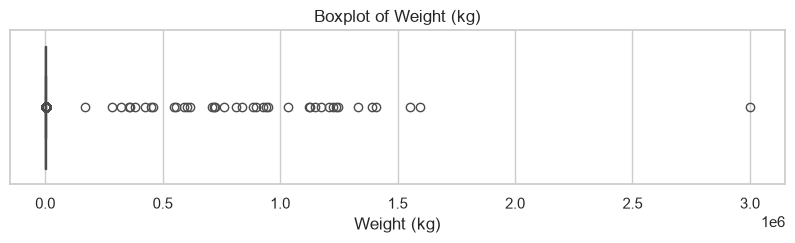

In [736]:
# Boxplot
plt.figure(figsize=(10, 2))

sns.boxplot(
    data=raw,
    x="weight_kg"
)

plt.title("Boxplot of Weight (kg)")
plt.xlabel("Weight (kg)")
plt.show()

In [737]:
print(f"Number of rows fo Weight higher than 30k: {(raw["weight_kg"] > 30000).sum()}")

#1000 times the min where appears the first outlier
heavy = raw.loc[raw["weight_kg"] > 30000, "weight_kg"]
heavy.describe()

Number of rows fo Weight higher than 30k: 40


count    4.000000e+01
mean     9.021825e+05
std      5.077007e+05
min      1.709000e+05
25%      5.542000e+05
50%      8.598500e+05
75%      1.182775e+06
max      2.999300e+06
Name: weight_kg, dtype: float64

 Those 40 values are between 170 and 3000 Tons, what is a imposible value for a truck. 

In [738]:
print(f"Number of rows fo Weight lower than 30k: {(raw["weight_kg"] < 30000).sum()}")

normal = raw.loc[raw["weight_kg"] < 30000, "weight_kg"]
normal.describe()

Number of rows fo Weight lower than 30k: 5995


count    5995.000000
mean      954.911693
std       620.264914
min        30.000000
25%       494.500000
50%       823.600000
75%      1275.200000
max      5044.000000
Name: weight_kg, dtype: float64

Because the span in magnitude of those 40 values, is better to plot the distribution in a log scale where I can see where are the outliers.

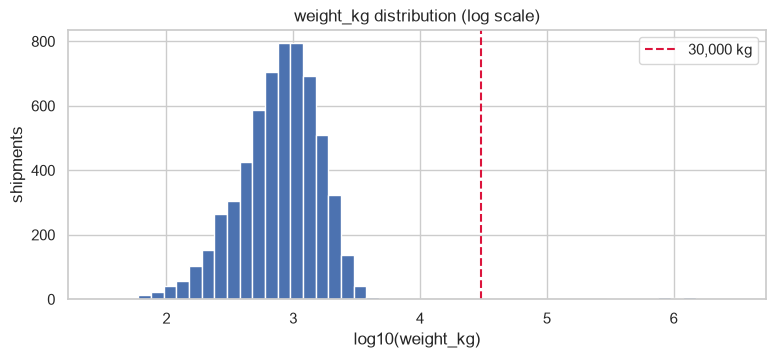

In [739]:
# weight_kg spans five orders of magnitude, so look at it on a log scale
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(np.log10(raw["weight_kg"]), bins=50, color="#4C72B0")
ax.axvline(np.log10(30_000), color="crimson", ls="--", label="30,000 kg")
ax.set(xlabel="log10(weight_kg)", ylabel="shipments", title="weight_kg distribution (log scale)")
ax.legend()
plt.show()

In [740]:
(heavy / 1000).describe()

count      40.000000
mean      902.182500
std       507.700671
min       170.900000
25%       554.200000
50%       859.850000
75%      1182.775000
max      2999.300000
Name: weight_kg, dtype: float64

Upon examining the distribution and characteristics of these values, I identified a distinct anomaly: it appears the values are recorded in grams. Therefore, by dividing them by 1,000, the values match the normal range and mean of the dataset. To ensure reproducibility, I divide values exceeding 30,000 by 1,000, as previously identified in the boxplot visualization, since setting a lower threshold could risk capturing values close to the upper extreme

In [741]:
# Leakage check: is the target simply actual_transit_hours > scheduled_transit_hours?
pd.crosstab(raw[TARGET], raw["actual_transit_hours"] > raw["scheduled_transit_hours"],
            rownames=[TARGET], colnames=["actual > scheduled"])

actual > scheduled,False,True
delivered_late,,
0,3218,1575
1,0,1242


Feature actual_transit_hours is only recorded upon delivery, and every late shipment is defined by actual > scheduled, including this feature causes data leakage, what forces the model to rely on post-delivery information for prediction.

## 3. Data preprocessing (cleaning)


1. Drop 32 identical rows duplicates and repeated ID

2. Inconsistent spelling: service_level has both Standard/standard Economy/economy Express/express. Normalise 

3. Unit error weight_kg values between 170,000 and 3,000,000, divided by 1,000 they fall in the normal 170 to 3,000 range.

4. Missing values Imputation
- fuel_cost_cad (240)
- driver_experience_years (210)
- weather_condition (150)
- traffic_index (121)
Impute inside the model pipeline with missing-value flags

5. Drop from features. Target leakage, actual_transit_hours`is recorded on delivery, and every late shipment has actual > scheduled


In [742]:
# Copy of the dataset to perform the cleaning
df = raw.copy()
log = {"rows_in": len(df)}

In [743]:
#Duplicates: 32 identical rows

df = df.drop_duplicates()
log["exact_duplicates_removed"] = log["rows_in"] - len(df)
n = len(df)

#Repeated shipment IDs (keep the first record)
df = df.drop_duplicates(subset="shipment_id", keep="first")
log["repeated_ids_removed"] = n - len(df)


# Inconsistent spelling: service_level has both Standard/standard Economy/economy Express/express
for col in df.select_dtypes(include=["object", "string"]).columns.drop("shipment_id"):
    df[col] = df[col].str.strip().str.lower()


# Unit error: weights entered in grams are converted back to kg
GRAMS_THRESHOLD_KG = 30000   
grams = df["weight_kg"] > GRAMS_THRESHOLD_KG
df.loc[grams, "weight_kg"] = df.loc[grams, "weight_kg"] / 1000
log["weights_converted_from_grams"] = int(grams.sum())

log["rows_out"] = len(df)


In [744]:
# Check the result
print("service_level:", sorted(df["service_level"].unique()))
print("weight_kg range:", df["weight_kg"].min(), "to", df["weight_kg"].max())
print("Duplicate IDs left:", df["shipment_id"].duplicated().sum())
print(f"Late rate after cleaning: {df[TARGET].mean():.1%}")

service_level: ['economy', 'express', 'standard']
weight_kg range: 30.0 to 5044.0
Duplicate IDs left: 0
Late rate after cleaning: 20.6%


## 4. Exploratory data analysis (EDA)
Goal: find thedrivers of late delivery

In [745]:
overall = df[TARGET].mean()

def late_rate_plot(cols, ncols=3, df=df):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.6 * nrows))
    for ax, col in zip(np.ravel(axes), cols):
        rate = df.groupby(col, observed=True)[TARGET].mean().sort_values()
        ax.barh(rate.index.astype(str), rate.values, color="#4C72B0")
        ax.axvline(overall, color="crimson", ls="--", lw=1)
        ax.set(title=col, xlabel="late rate")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()



Comparing each bar against the red average line:

High Risk (Far Right): Bars that extend to the right show categories with higher-than-average delay rates. These highlight operational bottlenecks.

Low Risk (Far Left): Bars that stay to the left show categories that perform better and experience fewer delays than average.

Low Impact (Close to the Line): If all bars align with the red line, the variable does not help distinguish late shipments from on-time ones. It adds little to no predictive value.

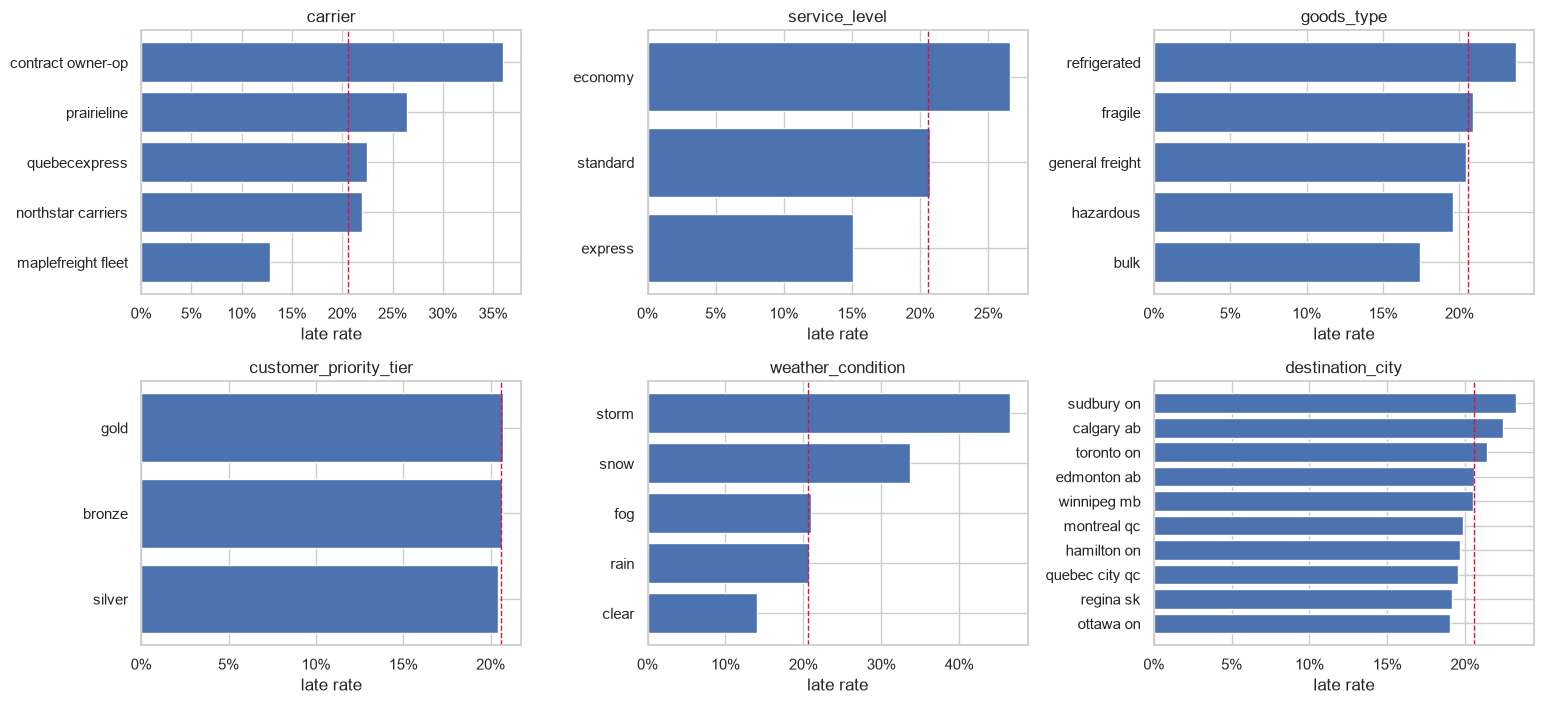

In [746]:
late_rate_plot(["carrier", "service_level", "goods_type",
                "customer_priority_tier", "weather_condition", "destination_city"])

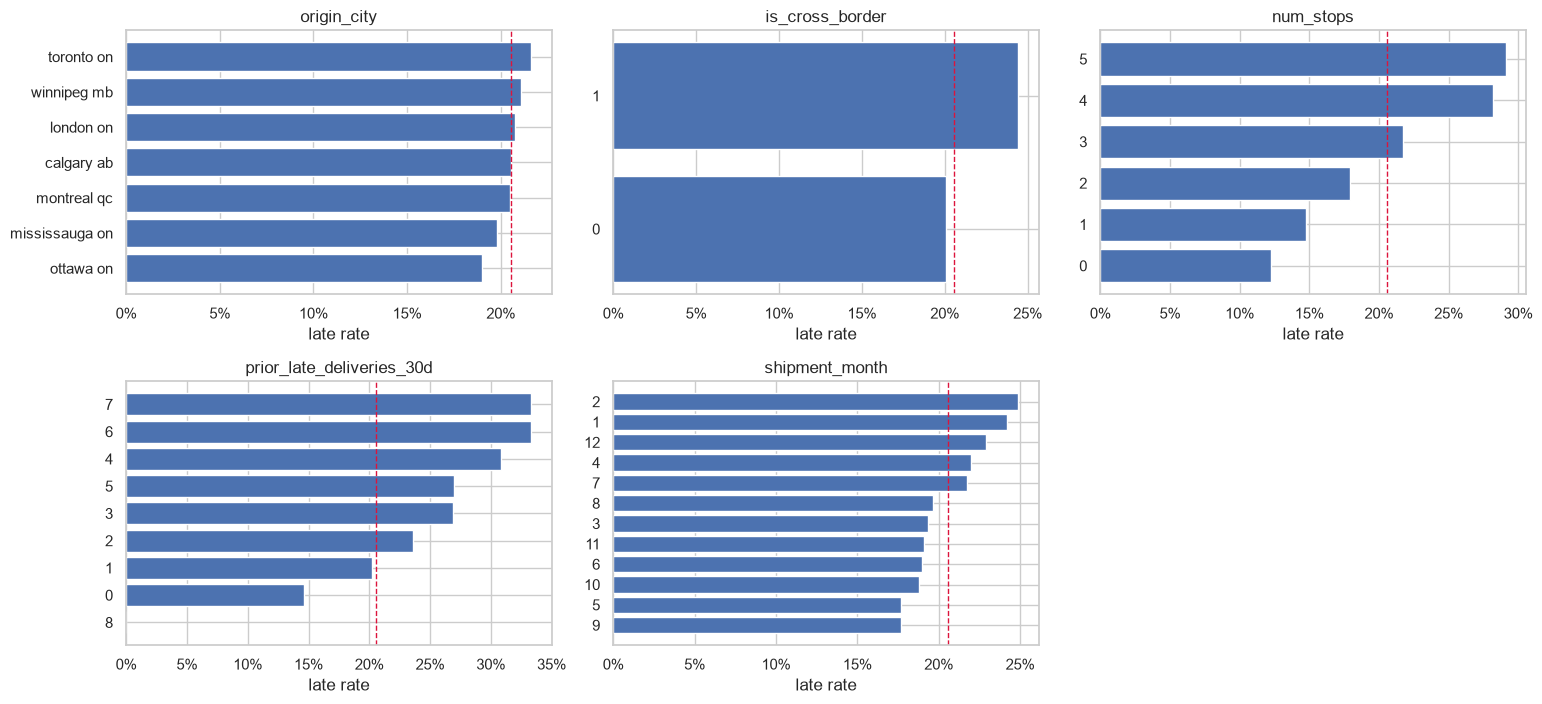

In [747]:
late_rate_plot(["origin_city", "is_cross_border", "num_stops",
                "prior_late_deliveries_30d", "shipment_month"])

 Weather is the strongest single signal (storm 46% and snow 34% late vs. 14% for clear). Contract owner-operators are late 36% of the time, almost three times the company fleet (13%). Late rate climbs steadily with the number of stops (12% with none, 29% with five) and is higher in winter. Customer tier and city show almost no signal; Gold accounts are late as often as Bronze (about 21%).


### 4.1 Numeric features: late vs. on-time
Box plots show whether late shipments differ from on-time ones on each numeric variable.

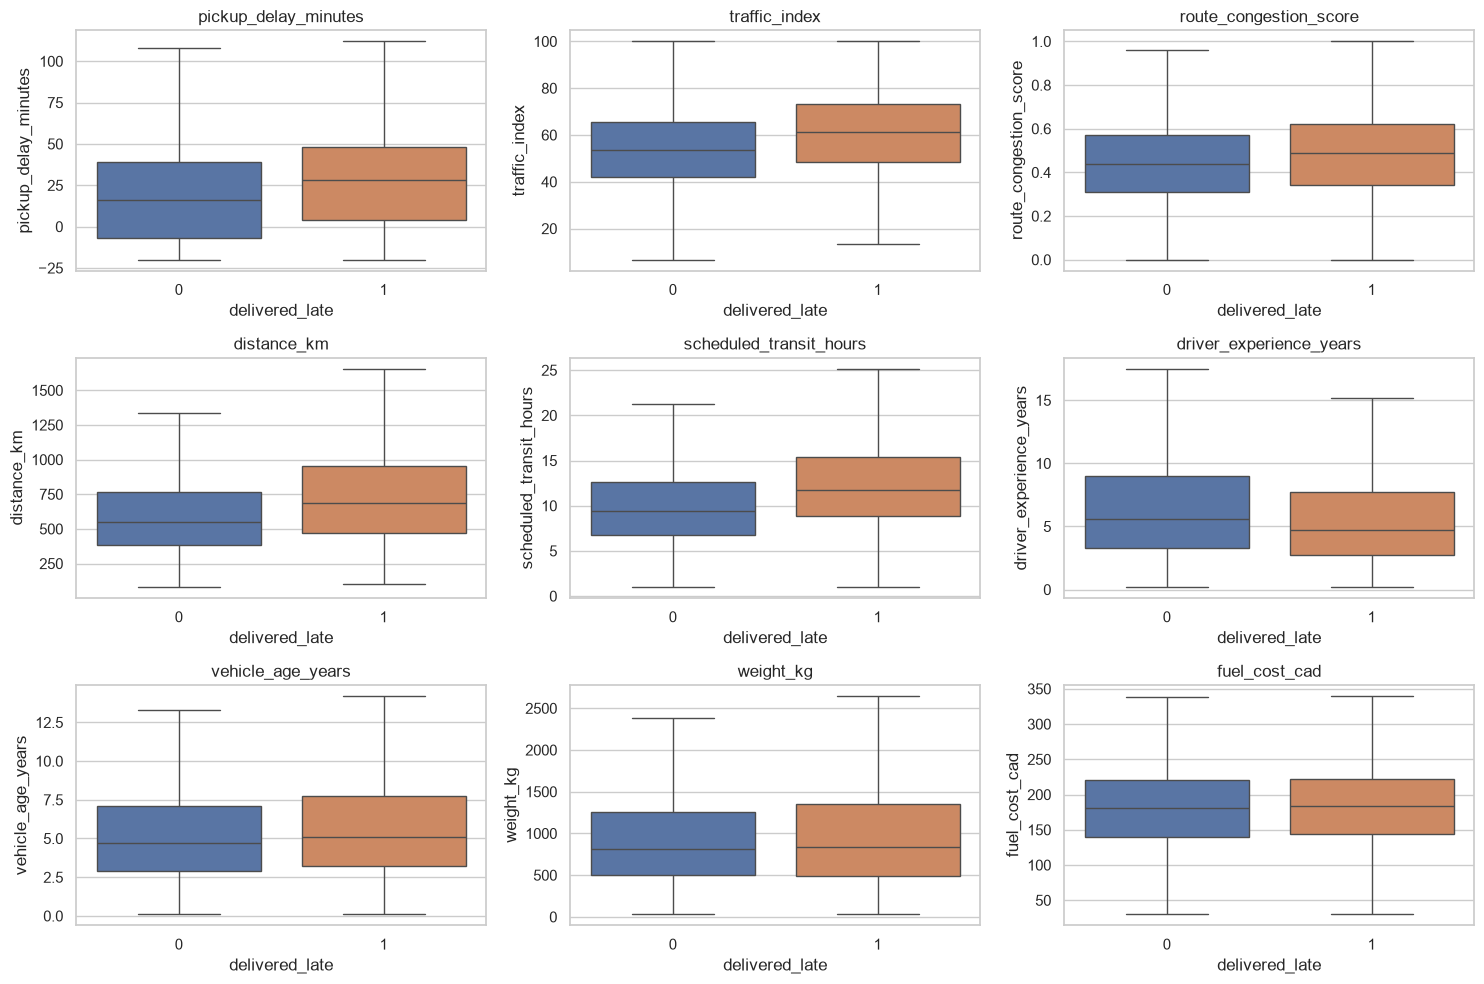

In [748]:
num_eda = ["pickup_delay_minutes", "traffic_index", "route_congestion_score", "distance_km",
           "scheduled_transit_hours", "driver_experience_years", "vehicle_age_years",
           "weight_kg", "fuel_cost_cad"]
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), num_eda):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, hue=TARGET, palette=["#4C72B0", "#DD8452"],
                legend=False, showfliers=False)
    ax.set(title=col, xlabel="delivered_late")
plt.tight_layout()
plt.show()

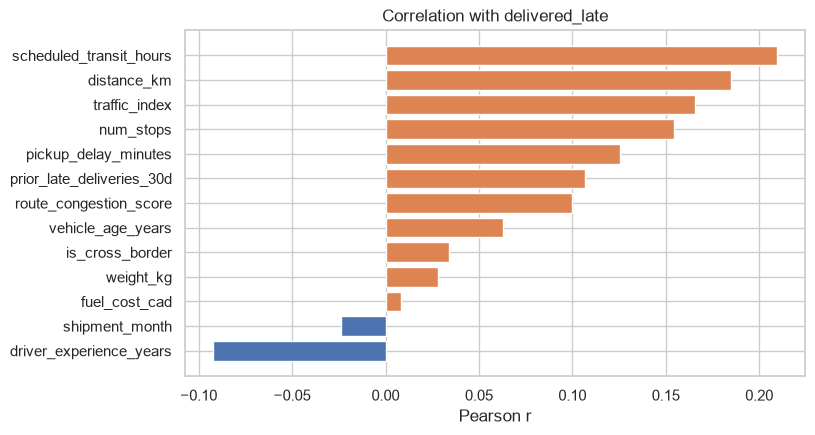

In [749]:
# Correlation of each numeric feature with the target 
num_cols_all = df.select_dtypes("number").columns.drop([TARGET, "actual_transit_hours"])
corr = df[num_cols_all].corrwith(df[TARGET]).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(corr.index, corr.values, color=np.where(corr > 0, "#DD8452", "#4C72B0"))
ax.set(title="Correlation with delivered_late", xlabel="Pearson r")
plt.show()

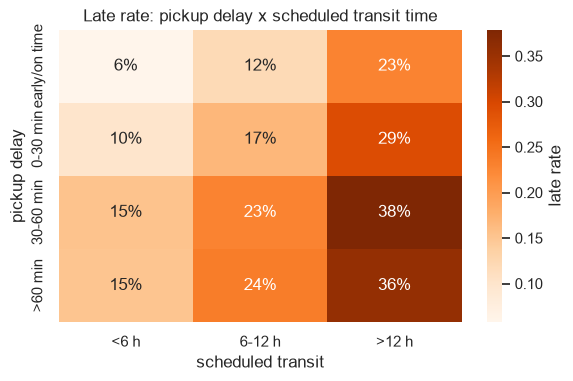

In [750]:
#  DEpendCrossing variables Does the effect of a late pickup depend on how long the trip is
df_eda = df.assign(
    pickup_delay_bin=pd.cut(df["pickup_delay_minutes"], [-np.inf, 0, 30, 60, np.inf],
                            labels=["early/on time", "0-30 min", "30-60 min", ">60 min"]),
    transit_bin=pd.cut(df["scheduled_transit_hours"], [0, 6, 12, np.inf],
                       labels=["<6 h", "6-12 h", ">12 h"]))
pivot = df_eda.pivot_table(index="pickup_delay_bin", columns="transit_bin", values=TARGET,
                           aggfunc="mean", observed=True)
plt.figure(figsize=(6.5, 3.8))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Oranges", cbar_kws={"label": "late rate"})
plt.title("Late rate: pickup delay x scheduled transit time")
plt.xlabel("scheduled transit"); plt.ylabel("pickup delay")
plt.show()

#### EDA findings (drivers of late delivery)

- Weather is the strongest single signal. Storm are late 46% of the time, snow 34% and 14% clear weather.
- Carrier: Contract owner-operators are late 36% of the time, almost 3 times the company's own fleet (13%)
- Service level: Economy is late 27% of the time, Express 15%.
- Route complexity: the late rate climbs persistently with the number of stops (12% with no stops, 29% with 5), with distance and scheduled transit time  0.19 to 0.21
- Conditions at dispatch: the most congested fifth of traffic is late 32% of the time vs. 12% for the least congested; historical route congestion shows 27% vs. 16%; a pickup more than 30 minutes late gives about 27% vs. 15% for an on-time pickup; carriers with 3 or 4 late deliveries in the last 30 days are late 27 to 31% of the time vs. 15% with none.
- Driver and vehicle: drivers with less than 3 years of experience are late 26% of the time vs. 14% for those with more than 10. The oldest vehicles show 25% vs. 17%.
- Little or no signal: customer tier (Gold, Silver and Bronze are all about 21%, so Gold accounts get no better service), destination city (19 to 23%), goods type (Refrigerated 24% vs. Bulk 17%) and month (January and February about 25%, mid-year about 18%).
- Risks add up. The heatmap shows a late pickup on a long trip is the worst case: 38% late for a pickup 30 to 60 minutes late on a trip over 12 hours, vs. 6% for an on-time pickup on a trip under 6 hours. The initial hypothesis that a late pickup hurts short trips more is not supported.

## 5. Feature engineering

In [751]:
LEAKAGE_COLS = ["actual_transit_hours"]
ID_COL = "shipment_id"
WEATHER_SEVERITY = {"clear": 0, "fog": 1, "rain": 1, "snow": 2, "storm": 3}
df = df.copy()
sched = df["scheduled_transit_hours"]

In [752]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    sched = df["scheduled_transit_hours"]

    # pickup_delay_ratio: pickup delay (h) / scheduled transit (h). Shows how much of the promised delivery window was already lost before the truck even departs.
    df["pickup_delay_ratio"] = (df["pickup_delay_minutes"] / 60) / sched

    # required_speed_kmh: distance / scheduled transit. Indicates how tight or demanding the promised schedule is.
    df["required_speed_kmh"] = df["distance_km"] / sched
    

    # hours_per_stop: scheduled transit / (stops + 1). Represents the amount of time available per leg of the trip.
    df["hours_per_stop"] = sched / (df["num_stops"] + 1)
    

    # weather_severity: clear = 0, fog = 1, rain = 1, snow = 2, storm = 3. An ordinal version of the weather forecast severity.
    df["weather_severity"] = df["weather_condition"].map(WEATHER_SEVERITY)   # NaN stays NaN and is imputed later
        

    # is_winter: month in December to March. Captures the seasonal effect observed in the exploratory data analysis.
    df["is_winter"] = df["shipment_month"].isin([12, 1, 2, 3]).astype(int)
        

    # log_weight_kg: log(1 + weight). Reduces skew in the weight distribution.
    df["log_weight_kg"] = np.log1p(df["weight_kg"])

    for col in ["driver_experience_years", "weather_condition", "traffic_index", "fuel_cost_cad"]:
        df[f"{col}_missing"] = df[col].isna().astype(int)
    return df.drop(columns=LEAKAGE_COLS, errors="ignore")


df.info()



<class 'pandas.DataFrame'>
Index: 6000 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6000 non-null   str    
 1   origin_city                6000 non-null   str    
 2   destination_city           6000 non-null   str    
 3   carrier                    6000 non-null   str    
 4   service_level              6000 non-null   str    
 5   goods_type                 6000 non-null   str    
 6   customer_priority_tier     6000 non-null   str    
 7   shipment_month             6000 non-null   int64  
 8   distance_km                6000 non-null   float64
 9   weight_kg                  6000 non-null   float64
 10  num_stops                  6000 non-null   int64  
 11  is_cross_border            6000 non-null   int64  
 12  scheduled_transit_hours    6000 non-null   float64
 13  pickup_delay_minutes       6000 non-null   float64
 14  driver_e

In [753]:
data = add_features(df)
engineered = ["pickup_delay_ratio", "required_speed_kmh", "hours_per_stop",
              "weather_severity", "is_winter", "log_weight_kg"]
data[engineered + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("corr with target")

,corr with target
weather_severity,0.216
is_winter,0.040
pickup_delay_ratio,0.028
log_weight_kg,0.016
hours_per_stop,0.006
required_speed_kmh,-0.043


Feature weather_severity is the only with a clear link to the target (r = 0.22, stronger than any raw numeric column). pickup_delay_ratio (r = 0.03) is much weaker than the raw pickup_delay_minutes (r = 0.13), which confirms the heatmap: losing a share of the window matters less than the absolute delay combined with a long trip. The other engineered features add little. They are kept and the models decide how much to use them. The missing-value flags carry almost no information (late rate of about 22% when a value is missing vs. 20.5% otherwise).

## 6. Data preparation

### 6.1 Train / test split
The data has a pickup month but no year, so a real time-based split is not possible. We use a **stratified 80/20 split**, which keeps 21% late shipments in both parts. The test set is used **once**, at the end, to compare the baseline with the final model. Model choice and threshold choice use cross-validation on the training set only.

In [754]:
CATEGORICAL = ["origin_city", "destination_city", "carrier", "service_level", "goods_type",
               "customer_priority_tier", "weather_condition"]
NUMERIC = ["shipment_month", "distance_km", "weight_kg", "log_weight_kg", "num_stops", "is_cross_border",
           "scheduled_transit_hours", "pickup_delay_minutes", "driver_experience_years",
           "vehicle_age_years", "traffic_index", "route_congestion_score", "prior_late_deliveries_30d",
           "fuel_cost_cad", "pickup_delay_ratio", "required_speed_kmh", "hours_per_stop",
           "weather_severity", "is_winter", "driver_experience_years_missing",
           "weather_condition_missing", "traffic_index_missing", "fuel_cost_cad_missing"]
FEATURES = CATEGORICAL + NUMERIC

X = data[FEATURES]
y = data[TARGET]
ids = data[ID_COL]

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, ids, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

pd.DataFrame({"rows": [len(X_train), len(X_test)],
              "late_rate": [y_train.mean(), y_test.mean()]},
             index=["train", "test"]).round(3)

,rows,late_rate
train,4800,0.206
test,1200,0.206


### 6.2 Preprocessing pipeline
A ColumnTransformer bundles every transformation, so it is **fit on the training data only** and applied in the same way to test data and to new shipments:
- **Numeric:** median imputation, then standard scaling (needed by logistic regression, harmless for trees).
- **Categorical:** missing values become "Unknown", then one-hot encoding. Categories never seen in training are ignored at scoring time.

Class imbalance is handled with class_weight="balanced", which gives each late shipment about 4 times the weight of an on-time one in the loss. This avoids creating synthetic rows (as SMOTE would) and cannot leak into validation folds.

In [755]:
numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
preprocessor = ColumnTransformer([("num", numeric_pipe, NUMERIC),
                                  ("cat", categorical_pipe, CATEGORICAL)])

def make_pipeline(model):
    return Pipeline([("prep", preprocessor), ("model", model)])

print("Model input width after encoding:",
      make_pipeline(DummyClassifier()).fit(X_train, y_train)[:-1].transform(X_train).shape[1], "columns")

Model input width after encoding: 62 columns


## 7. Data modelling

1. Logistic Regression
Used as a baseline model to establish a performance reference point.
- Simple and fast, easy to interpret, orks well when the relationship between features and the target is approximately linear and serves as a benchmark to compare whether more complex models truly provide an improvement


2. Random Forest 
Is an ensemble model based on multiple decision trees.
- It can capture non-linear relationships, it models interactions between variables, is less sensitive to outliers than some linear models, generally performs well on tabular data.


3. Hist Gradient Boosting
Hist Gradient Boosting also uses trees, but builds them sequentially, where each tree attempts to correct the errors made by the previous ones. It has better efficiency and performance with tabular data than normal GradientBoostingClassifier.
-It captures complex, non-linear relationships also can uncover patterns that linear models miss. This model usually offers strong predictive performance.


In [756]:

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict, RandomizedSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_curve, PrecisionRecallDisplay)


RANDOM_STATE = 42 # Repetibility
N_JOBS = 1  # Process in parallel      

In [757]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "pr_auc": "average_precision", "roc_auc": "roc_auc"}

candidates = {
    "Logistic Regression (baseline)": LogisticRegression(class_weight="balanced", max_iter=2000,
                                                         random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                             class_weight="balanced",
                                                             random_state=RANDOM_STATE),
}

cv_rows = {}
for name, model in candidates.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=N_JOBS)
    cv_rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}
cv_results = pd.DataFrame(cv_rows).T.round(3)
cv_results

,accuracy,precision,recall,f1,pr_auc,roc_auc
Logistic Regression (baseline),0.740,0.423,0.723,0.533,0.558,0.808
Random Forest,0.786,0.484,0.551,0.515,0.527,0.792
Hist Gradient Boosting,0.790,0.493,0.456,0.473,0.506,0.780


Logistic Regression showed the best performance identifying late shipments, mainly its capability, reflected in a recall of 0.723 and an ROC-AUC of 0.808. Random Forest and Hist Gradient Boosting achieved higher accuracy, identifiying a smaller proportion of actual delays. But as primary objective is to anticipate as many late deliveries as possible, Logistic Regression will be the most recomended. Also, its precision of 0.423 indicates that some delay predictions are false alarms. 

In [758]:
import os
import warnings
import requests
from dotenv import load_dotenv
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)   # the dummy model never predicts "late"


## 8. Model evaluation

### Choosing the alert threshold 
- False negative, a late shipment that was not detected: A service credit, an expedited re-delivery and an angry customer. That will be Expensive.
- False positive, a false alarm: A dispatcher spends a few minutes checking a shipment that would have arrived on time. Cheap, but too many of them can cause alert fatigue.

Recall is the priority, and taking the highest threshold that meets the recall target keeps precision as high as possible. The table also shows the F1-optimal threshold for comparison.

Current Baseline: The model currently achieves a 72% recall.



In [759]:
final_name = "Logistic Regression (baseline)"
final_pipe = make_pipeline(candidates[final_name])

baseline_pipe = final_pipe

print("Final model:", final_name)

Final model: Logistic Regression (baseline)


In [760]:
TARGET_RECALL1 = 0.72
TARGET_RECALL2 = 0.75
TARGET_RECALL3 = 0.80

oof_proba = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# scores that the model gave to shipments that were really late
late_scores = oof_proba[y_train.values == 1]


THRESHOLD1 = max(t for t in np.arange(0.001, 1, 0.001)
                if recall_score(y_train, oof_proba >= t) >= TARGET_RECALL1)
print(f"Threshold: {THRESHOLD1:.3f} with target recall {TARGET_RECALL1}")


THRESHOLD = max(t for t in np.arange(0.001, 1, 0.001)
                if recall_score(y_train, oof_proba >= t) >= TARGET_RECALL2)
print(f"Threshold: {THRESHOLD:.3f}  with target recall {TARGET_RECALL2}")

THRESHOLD2 = max(t for t in np.arange(0.001, 1, 0.001)
                if recall_score(y_train, oof_proba >= t) >= TARGET_RECALL3)
print(f"Threshold: {THRESHOLD2:.3f}  with target recall {TARGET_RECALL3}")

Threshold: 0.504 with target recall 0.72
Threshold: 0.467  with target recall 0.75
Threshold: 0.412  with target recall 0.8


### Threshold decision

The model outputs a risk score between 0 and 1, and the alert threshold decides which shipments are sent to Slack.
Recall is the priority: a missed late shipment (false negative) costs a service credit, an expedited re-delivery and a customer complaint, while a false alarm only costs a dispatcher a few minutes.

Recall vs. precision trade-off

- Raise the threshold (above 0.50): Fewer alerts and higher precision, but recall drops below 72% and more late shipments go undetected.

- Keep the threshold at 0.47 (recall ≥ 75%, chosen): Catches about 3 of every 4 late shipments at 40% precision, roughly twice the 21% base rate.

- Lower it further (80%–85% recall target): Captures more delays, but precision falls and the share of flagged shipments grows substantially.

Operational risk (Slack notifications)

- Too many false alarms create alert fatigue.
- If dispatch stops reading the channel because of the noise, real late shipments get ignored too, which defeats the purpose of the model.
- The chosen threshold must therefore balance catching delays with keeping alert volume manageable.

In [761]:
from sklearn.metrics import classification_report

# Train the model selected
final_pipe.fit(X_train, y_train)

# Probability of late shimpent
y_test_proba = final_pipe.predict_proba(X_test)[:, 1]

# Use the threshold 
y_test_pred = (y_test_proba >= THRESHOLD).astype(int)

# Report
print(f"Classification report: {final_name} with threshold {THRESHOLD:.2f}\n")

print(
    classification_report( y_test,y_test_pred,
        target_names=["On time", "Late"],
        digits=3
    )
)


Classification report: Logistic Regression (baseline) with threshold 0.47

              precision    recall  f1-score   support

     On time      0.925     0.737     0.820       953
        Late      0.431     0.769     0.552       247

    accuracy                          0.743      1200
   macro avg      0.678     0.753     0.686      1200
weighted avg      0.823     0.743     0.765      1200



In [762]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

tn, fp, fn, tp = cm.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

True negatives: 702
False positives: 251
False negatives: 57
True positives: 190


Evaluation findings
Final model on the test set (threshold 0.47): 

- Recall 0.769
- Precision 0.431
- F1 0.552 
- From the 247 shipments it catches  190 (recall 76%) late shipments and misses 57 (23%), at the cost of 251 false alarms